# Ridge Regression — Yuming ZHAI

## 1. Model Overview

We use Ridge Regression as a regularised linear reference model
for predicting single-family property sale prices in Cook County.

We use the shared eligible records, 81 input features and
chronological split. Numerical inputs will be standardised,
and categorical inputs will be one-hot encoded.

The regularisation parameter alpha will be selected using the
2024 validation set. The 2025 test set is reserved for final evaluation.

## 2. Load the Shared Data

The shared preprocessing has already filled missing values using
training-set medians and a separate "Missing" category.
We load these prepared datasets without repeating imputation.

In [1]:
import sys
sys.path.append("..")

from shared_preprocessing import load_splits, make_ridge_encoder

# Load the datasets prepared by the shared preprocessing notebook
X_train, y_train, X_val, y_val, X_test, y_test = load_splits(
    "../data/stage2_outputs"
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (276685, 81) (276685,)
Validation: (30545, 81) (30545,)
Test: (31535, 81) (31535,)


## 3. Initial Ridge Model

We first train Ridge Regression with alpha = 1.0.

The pipeline standardises numerical features and one-hot encodes
categorical features before fitting the model. Both the encoder
and the model are fitted on the training data only.

This initial model provides a reference before parameter tuning.

In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge

# Combine Ridge-specific preprocessing and the model
ridge_initial = make_pipeline(
    make_ridge_encoder(),
    Ridge(alpha=1.0, solver="lsqr")
)

# Fit preprocessing and the model using training data only
ridge_initial.fit(X_train, y_train)

print("Initial Ridge model trained successfully.")

Initial Ridge model trained successfully.


## 4. Validation Evaluation and Parameter Tuning

We evaluate the initial Ridge model and a training-mean baseline
on the 2024 validation set using MAE, RMSE and R².

We then compare alpha values of 0.1, 1, 10, 100 and 1000.
The model with the lowest validation RMSE is selected.
The 2025 test set is not used for parameter selection.

In [3]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Use the same metric definitions as the shared evaluation
def evaluate_predictions(name, y_true, y_pred):
    return {
        "model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

# Training-mean baseline evaluated on validation data
train_mean = float(y_train.mean())
baseline_predictions = np.full(len(y_val), train_mean)

baseline_result = evaluate_predictions(
    "Mean baseline", y_val, baseline_predictions
)

# Fit encoding once on training data and reuse it across alpha values
ridge_encoder = make_ridge_encoder()
X_train_encoded = ridge_encoder.fit_transform(X_train)
X_val_encoded = ridge_encoder.transform(X_val)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded validation shape:", X_val_encoded.shape)

alphas = [0.1, 1.0, 10.0, 100.0, 1000.0]
ridge_models = {}
tuning_results = []

for alpha in alphas:
    # Reuse the already-trained initial model for alpha = 1
    if alpha == 1.0:
        model = ridge_initial.named_steps["ridge"]
        predictions = ridge_initial.predict(X_val)
    else:
        model = Ridge(alpha=alpha, solver="lsqr")
        model.fit(X_train_encoded, y_train)
        predictions = model.predict(X_val_encoded)

    ridge_models[alpha] = model

    result = evaluate_predictions(
        f"Ridge alpha={alpha:g}", y_val, predictions
    )
    result["alpha"] = alpha
    tuning_results.append(result)

    print(
        f"alpha={alpha:g} | "
        f"MAE=${result['MAE']:,.2f} | "
        f"RMSE=${result['RMSE']:,.2f} | "
        f"R²={result['R2']:.4f}"
    )

tuning_table = (
    pd.DataFrame(tuning_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

best_alpha = float(tuning_table.loc[0, "alpha"])
best_ridge = ridge_models[best_alpha]

print(f"\nSelected alpha: {best_alpha:g}")

display(tuning_table.round(4))

validation_comparison = pd.DataFrame([
    baseline_result,
    evaluate_predictions(
        "Initial Ridge (alpha=1)",
        y_val,
        ridge_initial.predict(X_val)
    ),
    evaluate_predictions(
        f"Selected Ridge (alpha={best_alpha:g})",
        y_val,
        best_ridge.predict(X_val_encoded)
    )
])

display(validation_comparison.round(4))

Encoded training shape: (276685, 1163)
Encoded validation shape: (30545, 1163)
alpha=0.1 | MAE=$126,784.16 | RMSE=$231,855.09 | R²=0.7147
alpha=1 | MAE=$126,790.43 | RMSE=$231,865.00 | R²=0.7147
alpha=10 | MAE=$126,713.38 | RMSE=$231,940.10 | R²=0.7145
alpha=100 | MAE=$127,109.07 | RMSE=$233,164.26 | R²=0.7115
alpha=1000 | MAE=$130,041.88 | RMSE=$238,850.54 | R²=0.6972

Selected alpha: 0.1


,model,MAE,RMSE,R2,alpha
0,Ridge alpha=0.1,126784.1616,231855.0887,0.7147,0.1
1,Ridge alpha=1,126790.4349,231865.0035,0.7147,1.0
2,Ridge alpha=10,126713.3826,231940.0964,0.7145,10.0
3,Ridge alpha=100,127109.0656,233164.2571,0.7115,100.0
4,Ridge alpha=1000,130041.8753,238850.5382,0.6972,1000.0


,model,MAE,RMSE,R2
0,Mean baseline,227823.9716,444016.5549,-0.0463
1,Initial Ridge (alpha=1),126790.4349,231865.0035,0.7147
2,Selected Ridge (alpha=0.1),126784.1616,231855.0887,0.7147


### 4.1 Refine the Alpha Search

The initial search selected alpha = 0.1, the smallest tested value.
We therefore also evaluate 0.001 and 0.01 before fixing the model.

Selection is based on validation RMSE. The initial results show
very similar performance for alpha = 0.1 and alpha = 1, so small
differences should not be interpreted as substantial improvements.

In [4]:
for alpha in [0.001, 0.01]:
    model = Ridge(alpha=alpha, solver="lsqr")
    model.fit(X_train_encoded, y_train)
    predictions = model.predict(X_val_encoded)

    ridge_models[alpha] = model

    result = evaluate_predictions(
        f"Ridge alpha={alpha:g}", y_val, predictions
    )
    result["alpha"] = alpha
    tuning_results.append(result)

tuning_table = (
    pd.DataFrame(tuning_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

best_alpha = float(tuning_table.loc[0, "alpha"])
best_ridge = ridge_models[best_alpha]

print(f"Final selected alpha: {best_alpha:g}")
display(tuning_table.round(4))

Final selected alpha: 0.001


,model,MAE,RMSE,R2,alpha
0,Ridge alpha=0.001,126785.8230,231854.8719,0.7147,0.001
1,Ridge alpha=0.01,126785.6715,231854.8908,0.7147,0.010
2,Ridge alpha=0.1,126784.1616,231855.0887,0.7147,0.100
3,Ridge alpha=1,126790.4349,231865.0035,0.7147,1.000
4,Ridge alpha=10,126713.3826,231940.0964,0.7145,10.000
5,Ridge alpha=100,127109.0656,233164.2571,0.7115,100.000
6,Ridge alpha=1000,130041.8753,238850.5382,0.6972,1000.000


## 5. Final Test Evaluation

After selecting alpha using validation RMSE, we evaluate the
fixed model on the 2025 test set.

The encoder and model remain fitted on the 2017–2023 training data.
We report MAE, RMSE and R² on the original dollar scale and compare
against the training-mean baseline.

Test results will not be used to change the model or its parameters.

In [5]:
# Apply the training-fitted encoder without fitting again
X_test_encoded = ridge_encoder.transform(X_test)

val_predictions = best_ridge.predict(X_val_encoded)
test_predictions = best_ridge.predict(X_test_encoded)

test_baseline_predictions = np.full(len(y_test), train_mean)

final_results = pd.DataFrame([
    {
        **evaluate_predictions(
            "Mean baseline", y_val, baseline_predictions
        ),
        "split": "Validation 2024"
    },
    {
        **evaluate_predictions(
            "Ridge", y_val, val_predictions
        ),
        "split": "Validation 2024"
    },
    {
        **evaluate_predictions(
            "Mean baseline", y_test, test_baseline_predictions
        ),
        "split": "Test 2025"
    },
    {
        **evaluate_predictions(
            "Ridge", y_test, test_predictions
        ),
        "split": "Test 2025"
    }
])[["split", "model", "MAE", "RMSE", "R2"]]

print(f"Fixed alpha: {best_alpha:g}")
display(final_results.round(4))

negative_count = int((test_predictions < 0).sum())
print("Negative test predictions:", negative_count)
print("Predictions are evaluated without clipping.")

Fixed alpha: 0.001


,split,model,MAE,RMSE,R2
0,Validation 2024,Mean baseline,227823.9716,444016.5549,-0.0463
1,Validation 2024,Ridge,126785.8230,231854.8719,0.7147
2,Test 2025,Mean baseline,249127.9742,551842.5913,-0.0518
3,Test 2025,Ridge,147266.9869,348007.6634,0.5817


Negative test predictions: 214
Predictions are evaluated without clipping.


## 6. Error Analysis

We inspect predicted versus actual prices and signed prediction
errors on the test set. A fixed random sample is used for plotting;
evaluation metrics use all eligible records.

We also summarise errors across fixed actual-price bands.
Positive mean error indicates overprediction; negative mean error
indicates underprediction. These analyses describe the fixed model
and are not used for further tuning.

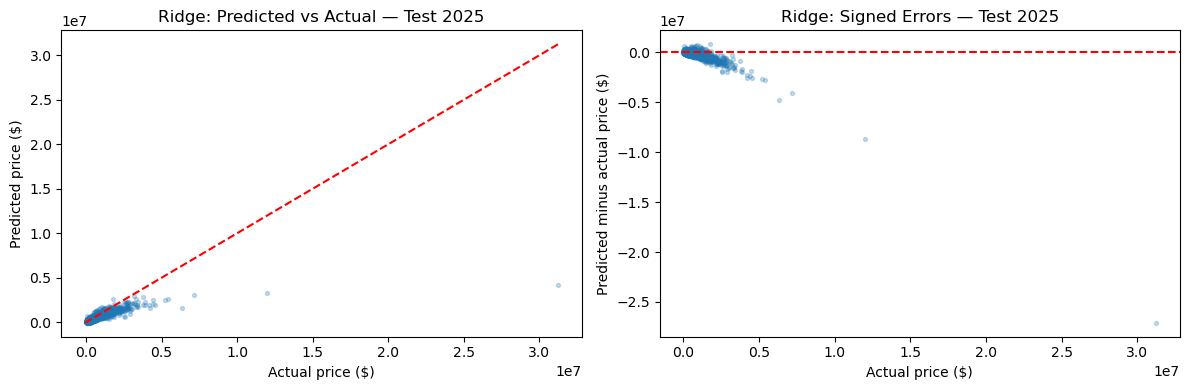

,records,MAE,mean_error
price_band,,,
Up to $250k,8694,69670.43,-18034.33
$250k–$500k,14348,104077.47,-85709.97
$500k–$1M,6070,177853.07,-144052.74
Above $1M,2423,604819.68,-579710.20


In [6]:
import matplotlib.pyplot as plt

test_errors = pd.DataFrame({
    "actual_price": np.asarray(y_test),
    "predicted_price": test_predictions
})

test_errors["error"] = (
    test_errors["predicted_price"] - test_errors["actual_price"]
)
test_errors["absolute_error"] = test_errors["error"].abs()

plot_sample = test_errors.sample(
    n=min(5000, len(test_errors)),
    random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(
    plot_sample["actual_price"],
    plot_sample["predicted_price"],
    s=8, alpha=0.25
)

lower = min(
    plot_sample["actual_price"].min(),
    plot_sample["predicted_price"].min()
)
upper = max(
    plot_sample["actual_price"].max(),
    plot_sample["predicted_price"].max()
)

axes[0].plot([lower, upper], [lower, upper], "r--")
axes[0].set_xlabel("Actual price ($)")
axes[0].set_ylabel("Predicted price ($)")
axes[0].set_title("Ridge: Predicted vs Actual — Test 2025")

axes[1].scatter(
    plot_sample["actual_price"],
    plot_sample["error"],
    s=8, alpha=0.25
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Actual price ($)")
axes[1].set_ylabel("Predicted minus actual price ($)")
axes[1].set_title("Ridge: Signed Errors — Test 2025")

plt.tight_layout()
plt.show()

test_errors["price_band"] = pd.cut(
    test_errors["actual_price"],
    bins=[0, 250_000, 500_000, 1_000_000, np.inf],
    labels=[
        "Up to $250k",
        "$250k–$500k",
        "$500k–$1M",
        "Above $1M"
    ],
    include_lowest=True
)

band_results = (
    test_errors.groupby("price_band", observed=True)
    .agg(
        records=("actual_price", "size"),
        MAE=("absolute_error", "mean"),
        mean_error=("error", "mean")
    )
)

display(band_results.round(2))

## 7. Export Results for the Group

We export the tuning results, final metrics and test predictions
for integration into the shared model comparison.

In [7]:
from pathlib import Path
import json

results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

tuning_table.to_csv(
    results_dir / "ridge_validation_tuning.csv", index=False
)
final_results.to_csv(
    results_dir / "ridge_metrics.csv", index=False
)
band_results.to_csv(
    results_dir / "ridge_errors_by_price_band.csv"
)

# Preserve source-row identifiers for alignment with shared metadata
predictions_export = test_errors.copy()
predictions_export.insert(
    0, "source_row_index", X_test.index.to_numpy()
)
predictions_export.to_csv(
    results_dir / "ridge_test_predictions.csv", index=False
)

(results_dir / "ridge_config.json").write_text(
    json.dumps({
        "alpha": best_alpha,
        "solver": "lsqr",
        "selection_metric": "validation RMSE",
        "training_period": "2017–2023",
        "validation_period": "2024",
        "test_period": "2025",
        "input_features": 81,
        "encoded_features": int(X_train_encoded.shape[1]),
        "target_transformation": "none",
        "prediction_clipping": False
    }, indent=2),
    encoding="utf-8"
)

print("Results saved to:", results_dir.resolve())

Results saved to: D:\zym\萨克雷相关\学习\Machine learning\cook-county-avm-main\results


## 8. Results and Discussion

### Parameter Selection

Among the seven tested alpha values, alpha = 0.001 achieved the
lowest validation RMSE and was selected.

However, validation performance was almost identical for alpha
values between 0.001 and 1. The RMSE difference between alpha = 0.001
and alpha = 0.1 was less than $1. This does not demonstrate a
meaningful advantage for the selected value. Stronger regularisation
at alpha = 100 and 1000 produced worse validation RMSE.

### Final Performance

| Model | Split | MAE (USD) | RMSE (USD) | R² |
|---|---|---:|---:|---:|
| Mean baseline | Validation 2024 | 227,823.97 | 444,016.55 | -0.0463 |
| Ridge | Validation 2024 | 126,785.82 | 231,854.87 | 0.7147 |
| Mean baseline | Test 2025 | 249,127.97 | 551,842.59 | -0.0518 |
| Ridge | Test 2025 | 147,266.99 | 348,007.66 | 0.5817 |

Ridge reduced test MAE by approximately 40.9% compared with the
training-mean baseline. It therefore learned useful relationships
between the selected features and sale prices.

Performance was weaker on the 2025 test set than on the 2024
validation set. Differences in the price distribution, extreme
sales and relationships between inputs and prices may contribute,
but the current analysis does not establish the cause.

### Errors Across Price Bands

| Actual price band (USD) | Records | MAE (USD) | Mean signed error (USD) |
|---|---:|---:|---:|
| Up to 250,000 | 8,694 | 69,670.43 | -18,034.33 |
| 250,000–500,000 | 14,348 | 104,077.47 | -85,709.97 |
| 500,000–1,000,000 | 6,070 | 177,853.07 | -144,052.74 |
| Above 1,000,000 | 2,423 | 604,819.68 | -579,710.20 |

Signed error is defined as predicted price minus actual price.
Its negative mean in every band indicates average underprediction.
Absolute dollar errors increase across the price bands, with
particularly large underprediction for properties above $1M.

The plots also show substantial underprediction for some extreme
high-price sales. RMSE is sensitive to these large errors.
These observations do not establish that the expensive sales
are incorrect records.

### Limitations

The unconstrained linear model produced 214 negative predictions
on the test set, approximately 0.68% of test records. Predictions
were evaluated without clipping. Negative prices are not plausible
and represent a limitation of this model.

Ridge uses an additive linear structure and may miss nonlinear
relationships and interactions. The chronological evaluation also
includes properties previously observed during training.

Historical availability has not been verified for every contextual
input. Results should therefore be interpreted as a retrospective
comparison under the documented dataset assumptions, rather than
evidence of fully verified real-time forecasting performance.

## 9. Conclusion

We trained and tuned Ridge Regression using the shared 81 inputs,
training-only preprocessing and chronological data split.

Ridge substantially improved on the mean-price baseline, but its
test performance was weaker than its validation performance.
Error analysis identified underprediction, especially for expensive
properties, and a small proportion of negative predictions.

Ridge provides a useful linear reference for comparison with
Random Forest and Gradient Boosting. With more time, we would
verify feature availability and investigate nonlinear features
or a log-price target using a new validation protocol. The current
test results will not be used to retune the model.